# Swedish climate diversity

Compare three explicit stations as climate examples, without inferring national spatial coverage from three locations.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW.

## Understanding the API in this lesson

The three `ClimateSpec` objects isolate climate variation through explicit EPW identities. Gothenburg, Malmö and Kiruna illustrate a geographic span, but three stations do not establish national spatial coverage or a station-selection rule.

The coordinate scatter shows station locations, the distributions show hourly variability and the monthly curves show seasonality. The existing context-sensitivity figure extends this idea with a separate retained experiment: the same shading question can have different heating and cooling consequences under different climates. Its numerical results are reference evidence, not values computed by the cells below.

Reference: [Retained example: context sensitivity across three climates](../../docs/figures/context-sensitivity.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Resolve station identities

Each path is explicit and checksum-verified. These TMY files are comparison inputs, not observations of a single common historical year.

### Read the code and output

Longitude and latitude are station metadata in degrees, unlike the metre coordinates required for building footprints. Do not pass this scatter's coordinates into `Footprint` without a caller-owned coordinate transformation. The filename and hash are the evidence needed to identify each forcing file again.

,city,epw_path,weather_sha256,latitude_deg,longitude_deg,elevation_m,time_zone_hours,calendar_year
0,Gothenburg,/Users/ssanjay/GitHub/epsm_core/data/weather/S...,99f6df726debe1f7df19317227ced9685fa3cf9d031bd5...,57.6761,12.2919,155.2,1.0,2023
1,Malmo,/Users/ssanjay/GitHub/epsm_core/data/weather/S...,807a1a5ce91263890512f941d99f80db27a6c424a0c6fe...,55.5231,13.3789,73.0,1.0,2023
2,Kiruna,/Users/ssanjay/GitHub/epsm_core/data/weather/S...,57e4b63ef2d5c59e23b4c2c181bfe12faf004f3d089add...,67.8228,20.3400,446.7,1.0,2023


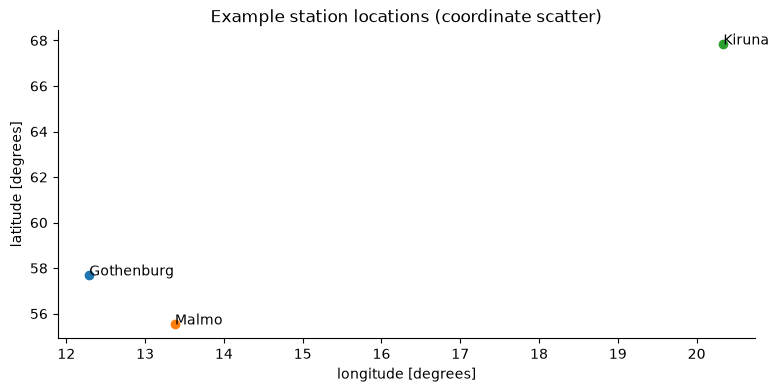

In [2]:
cities = ["Gothenburg","Malmo","Kiruna"]
climates = {city:climate_from_epw(epw(city)) for city in cities}
table([{"city":city, **c.model_dump()} for city,c in climates.items()])
fig,ax = plt.subplots(figsize=(9, 4))
for city,c in climates.items():
    ax.scatter(c.longitude_deg,c.latitude_deg); ax.annotate(city,(c.longitude_deg,c.latitude_deg))
ax.set(xlabel="longitude [degrees]",ylabel="latitude [degrees]",title="Example station locations (coordinate scatter)")
plt.show(); plt.close(fig)

## Compare distributions and seasonality

Averages hide cold extremes and summer variation. Plot both the distribution and the monthly mean before choosing representative climate classes.

### Read the code and output

A broad temperature distribution tells you more about seasonal and diurnal variation than a single annual mean. Compare the monthly curves to locate the period of largest separation between climates. The same operational schedule can produce a different heating season even when the physical building is unchanged.

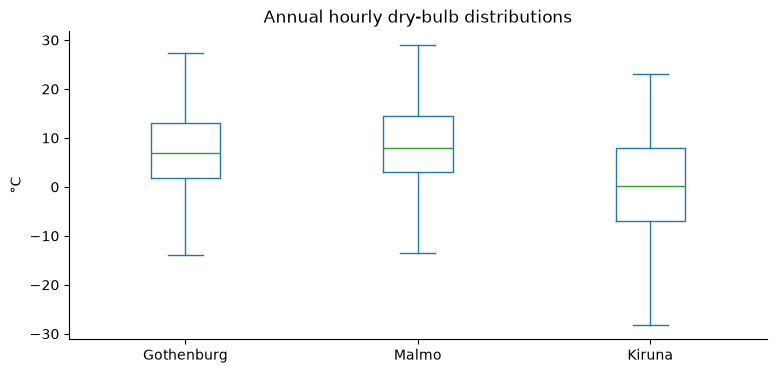

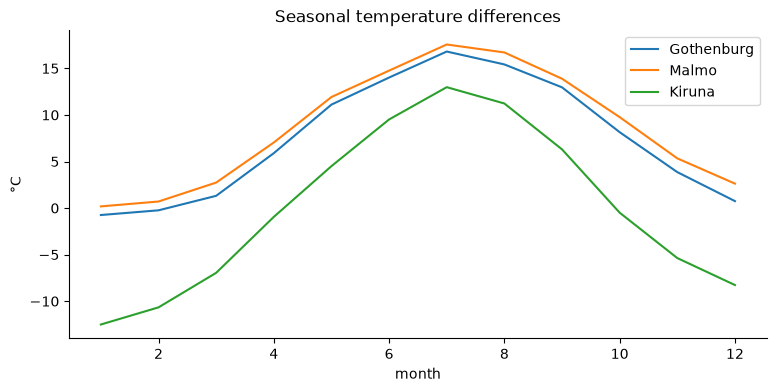

In [3]:
weather = {city:weather_frame(epw(city)) for city in cities}
fig, ax = plt.subplots(figsize=(9, 4))
pd.DataFrame({city:w.temperature_c for city,w in weather.items()}).plot.box(ax=ax, ylabel="°C",title="Annual hourly dry-bulb distributions")
plt.show(); plt.close(fig)
fig, ax = plt.subplots(figsize=(9, 4))
pd.DataFrame({city:w.groupby("month").temperature_c.mean() for city,w in weather.items()}).plot(ax=ax, ylabel="°C",title="Seasonal temperature differences")
plt.show(); plt.close(fig)

## Compare solar forcing

Global horizontal irradiation is not facade irradiation or PV generation. Roof/facade orientation and shading must be considered separately.

### Read the code and output

Annual global horizontal irradiation is a useful forcing summary, but it is not energy received by every facade. Orientation, tilt and shading affect surface exposure. Use the PV notebook or an actual building simulation for the corresponding modelled response rather than multiplying this total by arbitrary facade area.

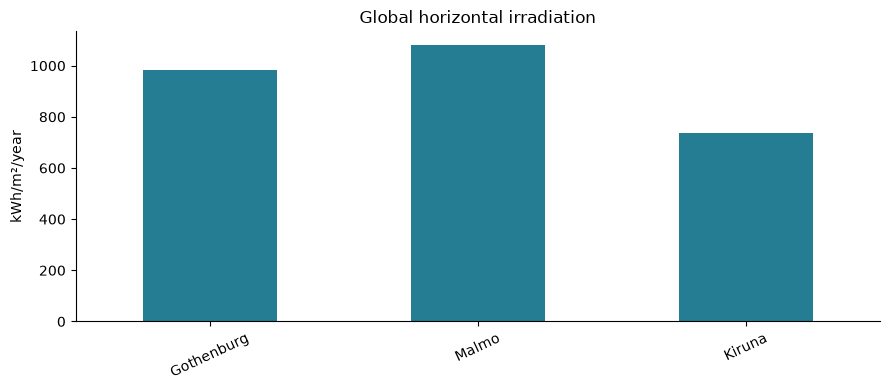

In [4]:
bars({city:w.global_horizontal_wh_m2.sum()/1000 for city,w in weather.items()}, "kWh/m²/year", "Global horizontal irradiation")
assert len({c.weather_sha256 for c in climates.values()}) == 3

## Interpretation and next experiment

A national workflow should select climate inputs from a documented spatial rule upstream. This notebook exercises explicit ClimateSpec diversity only.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.